# Flex travel allocation - analysis
Exploratory notebook for the presentation: visualise the resulting travel
distributions by product, date and hour. Run manually on non-production only.
All logic lives in the model modules; this notebook orchestrates and plots.

In [1]:
# Setup cell
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession

from conf.config import SEED, ENVIRONMENT_NON_PRODUCTION, Table, TravelDirection
from flex_travel_allocation.allocation import allocate_sales_to_travels
from flex_travel_allocation.analysis import (
    travels_by_date,
    travels_by_hour,
    travels_by_hour_and_direction,
    travels_by_product,
)
from flex_travel_allocation.data_handler import DataHandler
from flex_travel_allocation.ingestion import (
    clean_activations,
    clean_articles,
    clean_hours_between_probabilities,
    clean_minutes_to_add_probabilities,
    clean_sales,
)

spark = SparkSession.builder.getOrCreate()
data_handler = DataHandler.from_config(spark=spark, environment=ENVIRONMENT_NON_PRODUCTION)

In [2]:
# Read inputs and allocate
articles = data_handler.read_table(Table.ARTICLES).transform(clean_articles)
sales = data_handler.read_table(Table.SALES).transform(clean_sales)
activations = data_handler.read_table(Table.ACTIVATIONS).transform(clean_activations)
minutes_distribution = data_handler.read_table(
    Table.MINUTES_TO_ADD_PROBABILITIES
).transform(clean_minutes_to_add_probabilities)
hours_distribution = data_handler.read_table(
    Table.HOURS_BETWEEN_PROBABILITIES
).transform(clean_hours_between_probabilities)

travels = allocate_sales_to_travels(
    sales=sales,
    articles=articles,
    activations=activations,
    minutes_distribution=minutes_distribution,
    hours_distribution=hours_distribution,
    seed=SEED,
).cache()

## Travels by product

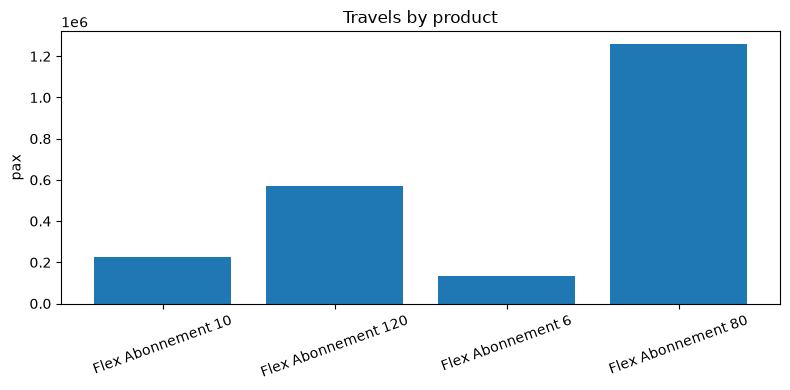

In [3]:
product_pdf = travels_by_product(travels).toPandas()
plt.figure(figsize=(8, 4))
plt.bar(product_pdf["article_description_nl"], product_pdf["pax"])
plt.ylabel("pax")
plt.title("Travels by product")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Travels by date

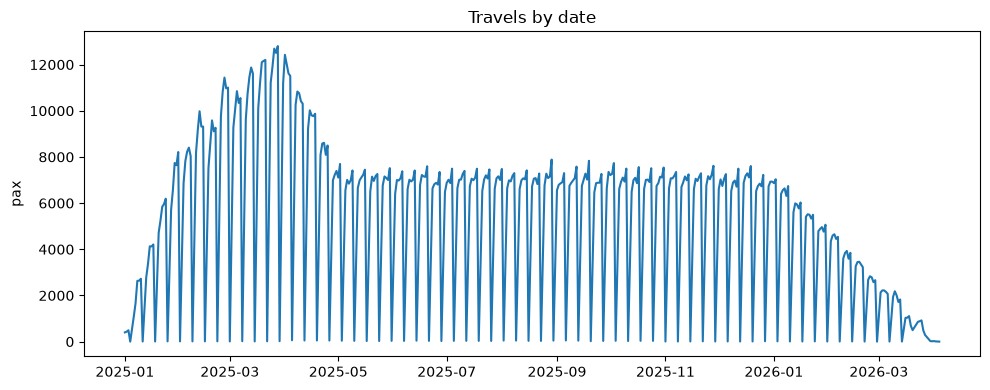

In [4]:
date_pdf = travels_by_date(travels).toPandas()
plt.figure(figsize=(10, 4))
plt.plot(date_pdf["travel_date"], date_pdf["pax"])
plt.ylabel("pax")
plt.title("Travels by date")
plt.tight_layout()
plt.show()

## Travels by hour

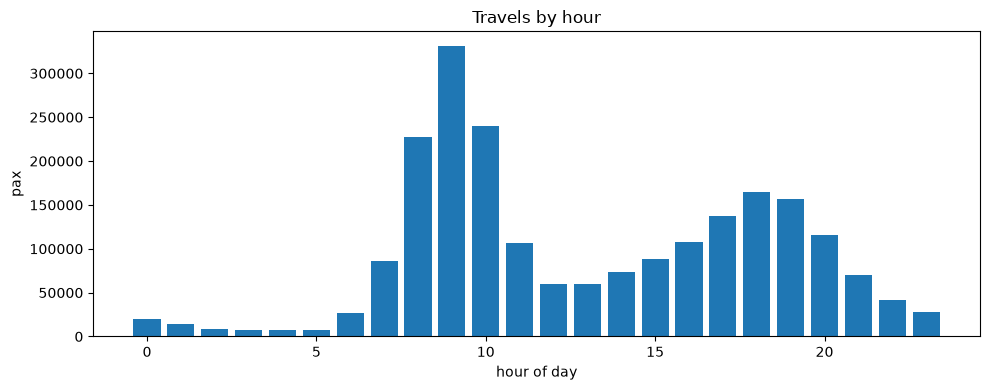

In [5]:
hour_pdf = travels_by_hour(travels).toPandas()
plt.figure(figsize=(10, 4))
plt.bar(hour_pdf["travel_hour"], hour_pdf["pax"])
plt.xlabel("hour of day")
plt.ylabel("pax")
plt.title("Travels by hour")
plt.tight_layout()
plt.show()

## Travels by hour and direction
There-travels concentrate in the morning peak, back-travels in the evening peak.

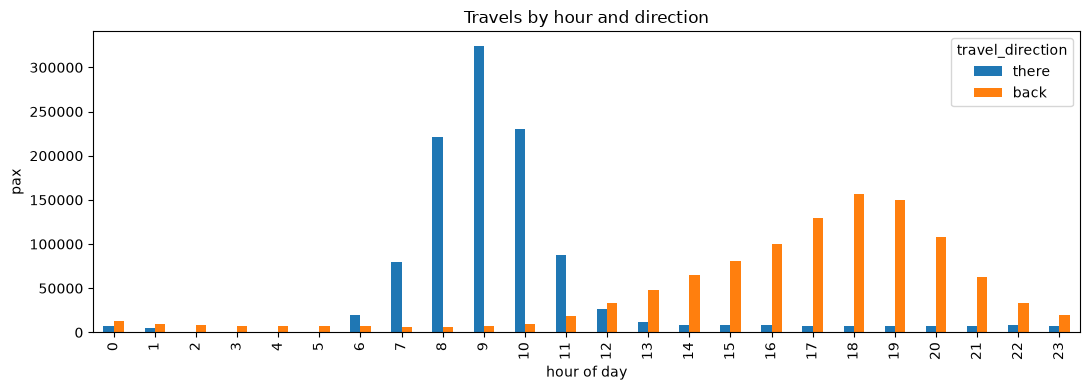

In [6]:
direction_pdf = travels_by_hour_and_direction(travels).toPandas()
pivot = direction_pdf.pivot(index="travel_hour", columns="travel_direction", values="pax").fillna(0)
pivot = pivot.rename(
    columns={TravelDirection.THERE.value: "there", TravelDirection.BACK.value: "back"}
)
pivot.plot(kind="bar", figsize=(11, 4))
plt.xlabel("hour of day")
plt.ylabel("pax")
plt.title("Travels by hour and direction")
plt.tight_layout()
plt.show()